# Original Qiskit qGAN reproduction

All original code cells from `GAN_01.ipynb` are executed unchanged, including `Sampler()` without a seed, 50 epochs, losses, and plotting. Only this introduction and a final diagnostic cell are added. The source notebook is preserved. Results are one stochastic run, not an exact recreation of the published measurement draws.

Reference: https://qiskit-community.github.io/qiskit-machine-learning/tutorials/04_torch_qgan.html

Copyright IBM 2017, 2026. Original tutorial code is licensed under Apache-2.0.

In [1]:
import torch
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = 123456
_ = torch.manual_seed(123456)  # suppress output

In [2]:
import numpy as np

num_dim = 2
num_discrete_values = 8
num_qubits = num_dim * int(np.log2(num_discrete_values))

In [3]:
from scipy.stats import multivariate_normal

coords = np.linspace(-2, 2, num_discrete_values)
rv = multivariate_normal(mean=[0.0, 0.0], cov=[[1, 0], [0, 1]], seed=algorithm_globals.random_seed)
grid_elements = np.transpose([np.tile(coords, len(coords)), np.repeat(coords, len(coords))])
prob_data = rv.pdf(grid_elements)
prob_data = prob_data / np.sum(prob_data)

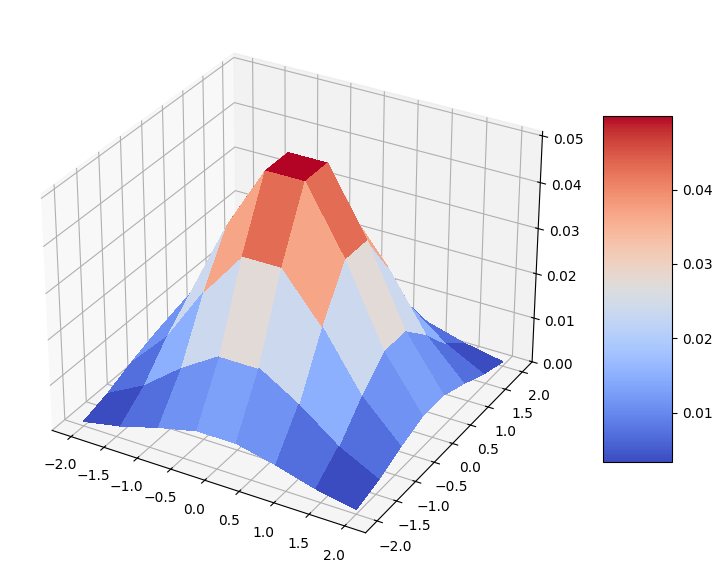

In [4]:
import matplotlib.pyplot as plt
from matplotlib import cm

mesh_x, mesh_y = np.meshgrid(coords, coords)
grid_shape = (num_discrete_values, num_discrete_values)

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={"projection": "3d"})
prob_grid = np.reshape(prob_data, grid_shape)
surf = ax.plot_surface(mesh_x, mesh_y, prob_grid, cmap=cm.coolwarm, linewidth=0, antialiased=False)
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import efficient_su2

qc = QuantumCircuit(num_qubits)
qc.h(qc.qubits)

ansatz = efficient_su2(num_qubits, reps=6)
qc.compose(ansatz, inplace=True)

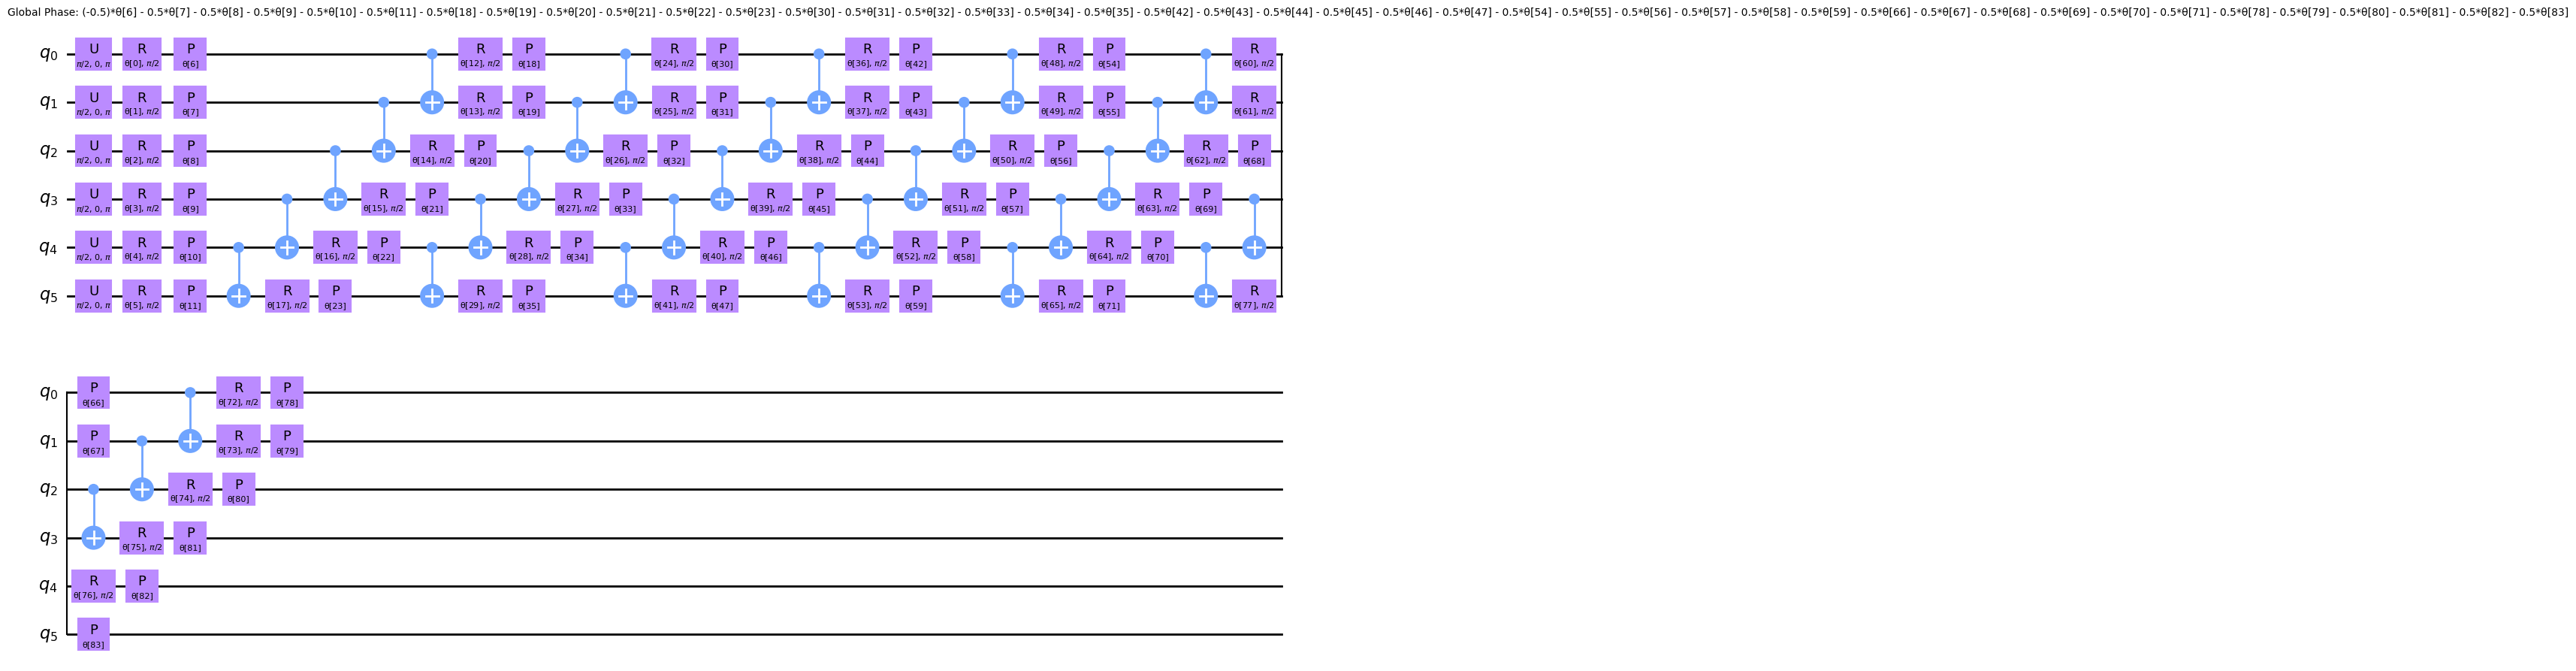

In [6]:
qc.decompose().draw(output="mpl", style="clifford")

In [7]:
qc.num_parameters

84

In [8]:
from qiskit.primitives import StatevectorSampler as Sampler

sampler = Sampler()

In [9]:
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import SamplerQNN


def create_generator() -> TorchConnector:
    qnn = SamplerQNN(
        circuit=qc,
        sampler=sampler,
        input_params=[],
        weight_params=qc.parameters,
        sparse=False,
    )

    initial_weights = algorithm_globals.random.random(qc.num_parameters)
    return TorchConnector(qnn, initial_weights)

In [10]:
from torch import nn


class Discriminator(nn.Module):
    def __init__(self, input_size):
        super(Discriminator, self).__init__()

        self.linear_input = nn.Linear(input_size, 20)
        self.leaky_relu = nn.LeakyReLU(0.2)
        self.linear20 = nn.Linear(20, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        x = self.linear_input(input)
        x = self.leaky_relu(x)
        x = self.linear20(x)
        x = self.sigmoid(x)
        return x

In [11]:
generator = create_generator()
discriminator = Discriminator(num_dim)

In [12]:
def adversarial_loss(input, target, w):
    bce_loss = target * torch.log(input) + (1 - target) * torch.log(1 - input)
    weighted_loss = w * bce_loss
    total_loss = -torch.sum(weighted_loss)
    return total_loss

In [13]:
from torch.optim import Adam

lr = 0.01  # learning rate
b1 = 0.7  # first momentum parameter
b2 = 0.999  # second momentum parameter

generator_optimizer = Adam(generator.parameters(), lr=lr, betas=(b1, b2), weight_decay=0.005)
discriminator_optimizer = Adam(
    discriminator.parameters(), lr=lr, betas=(b1, b2), weight_decay=0.005
)

In [14]:
from IPython.display import clear_output


def plot_training_progress():
    # we don't plot if we don't have enough data
    if len(generator_loss_values) < 2:
        return

    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))

    # Generator Loss
    ax1.set_title("Loss")
    ax1.plot(generator_loss_values, label="generator loss", color="royalblue")
    ax1.plot(discriminator_loss_values, label="discriminator loss", color="magenta")
    ax1.legend(loc="best")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Loss")
    ax1.grid()

    # Relative Entropy
    ax2.set_title("Relative entropy")
    ax2.plot(entropy_values)
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Relative entropy")
    ax2.grid()

    plt.show()

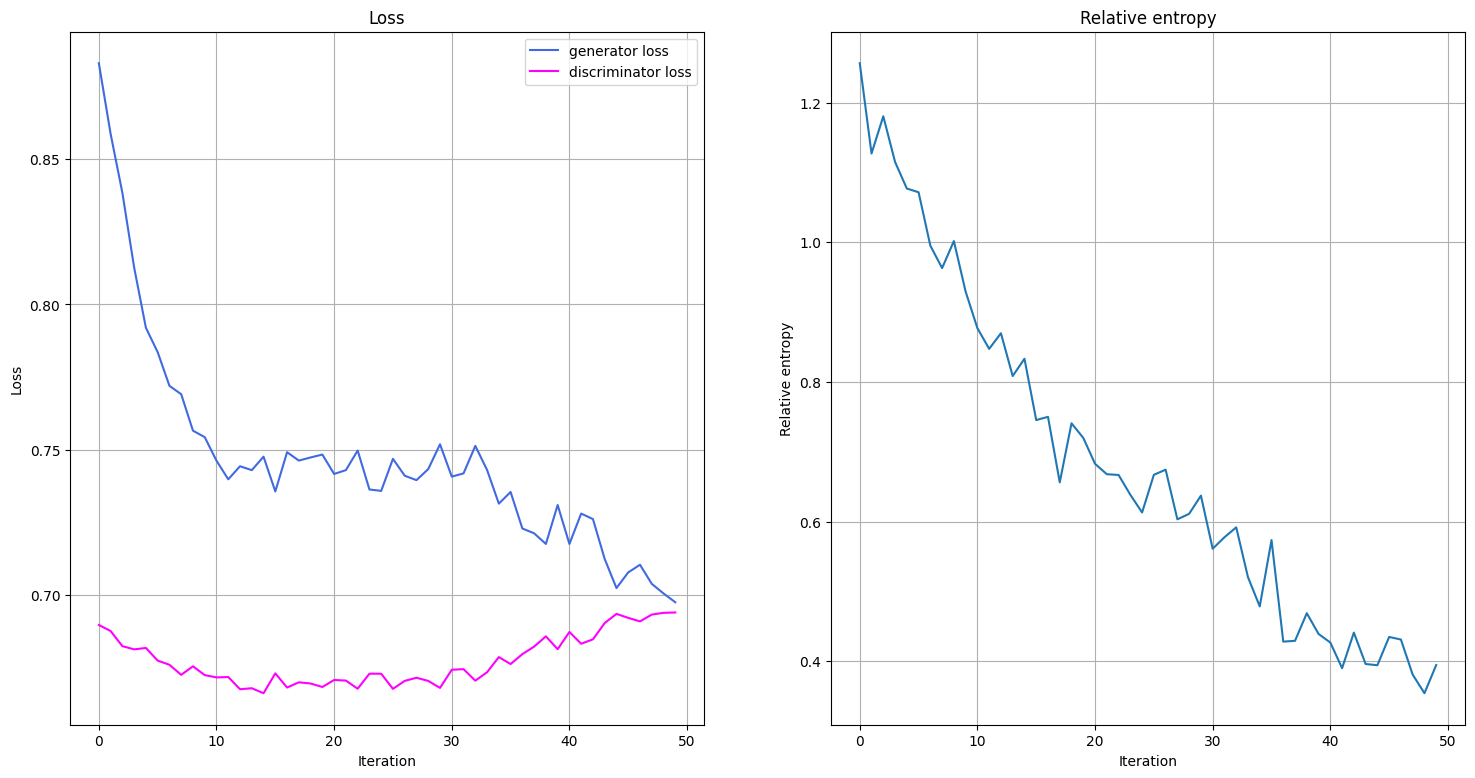

Fit in 111.69 sec


In [15]:
import time
from scipy.stats import multivariate_normal, entropy

n_epochs = 50

num_qnn_outputs = num_discrete_values**num_dim

generator_loss_values = []
discriminator_loss_values = []
entropy_values = []

start = time.time()
for epoch in range(n_epochs):

    valid = torch.ones(num_qnn_outputs, 1, dtype=torch.float)
    fake = torch.zeros(num_qnn_outputs, 1, dtype=torch.float)

    # Configure input
    real_dist = torch.tensor(prob_data, dtype=torch.float).reshape(-1, 1)

    # Configure samples
    samples = torch.tensor(grid_elements, dtype=torch.float)
    disc_value = discriminator(samples)

    # Generate data
    gen_dist = generator(torch.tensor([])).reshape(-1, 1)

    # Train generator
    generator_optimizer.zero_grad()
    generator_loss = adversarial_loss(disc_value, valid, gen_dist)

    # store for plotting
    generator_loss_values.append(generator_loss.detach().item())

    generator_loss.backward(retain_graph=True)
    generator_optimizer.step()

    # Train Discriminator
    discriminator_optimizer.zero_grad()

    real_loss = adversarial_loss(disc_value, valid, real_dist)
    fake_loss = adversarial_loss(disc_value, fake, gen_dist.detach())
    discriminator_loss = (real_loss + fake_loss) / 2

    # Store for plotting
    discriminator_loss_values.append(discriminator_loss.detach().item())

    discriminator_loss.backward()
    discriminator_optimizer.step()

    entropy_value = entropy(gen_dist.detach().squeeze().numpy(), prob_data)
    entropy_values.append(entropy_value)

    plot_training_progress()

elapsed = time.time() - start
print(f"Fit in {elapsed:0.2f} sec")

In [16]:
with torch.no_grad():
    generated_probabilities = generator().numpy()

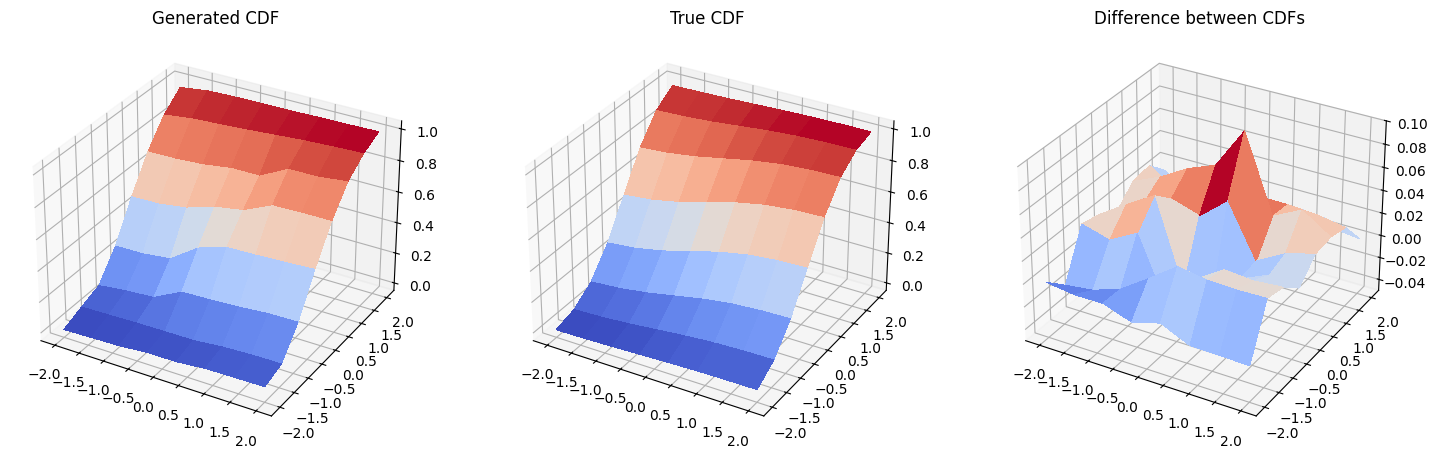

In [17]:
fig = plt.figure(figsize=(18, 9))

# Generated CDF
gen_prob_grid = np.reshape(np.cumsum(generated_probabilities), grid_shape)

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.set_title("Generated CDF")
ax1.plot_surface(mesh_x, mesh_y, gen_prob_grid, linewidth=0, antialiased=False, cmap=cm.coolwarm)
ax1.set_zlim(-0.05, 1.05)

# Real CDF
real_prob_grid = np.reshape(np.cumsum(prob_data), grid_shape)

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.set_title("True CDF")
ax2.plot_surface(mesh_x, mesh_y, real_prob_grid, linewidth=0, antialiased=False, cmap=cm.coolwarm)
ax2.set_zlim(-0.05, 1.05)

# Difference
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.set_title("Difference between CDFs")
ax3.plot_surface(
    mesh_x, mesh_y, real_prob_grid - gen_prob_grid, linewidth=2, antialiased=False, cmap=cm.coolwarm
)
ax3.set_zlim(-0.05, 0.1)
plt.show()

In [18]:
from importlib.metadata import PackageNotFoundError, version

for pkg in ("qiskit", "qiskit-machine-learning", "torch", "numpy", "scipy", "matplotlib"):
    try:
        print(f"{pkg:<26}{version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg:<26}not installed")

qiskit                    2.3.1
qiskit-machine-learning   0.9.1
torch                     2.14.1+cpu
numpy                     2.3.2
scipy                     1.16.1
matplotlib                3.10.5


In [19]:

import json, sys, platform, hashlib
from importlib.metadata import version
from pathlib import Path
from qiskit.quantum_info import Statevector

out = Path('C:\\Users\\giuse\\Documents\\Master\\DOUBT_QC\\tutorial_reproduction\\qiskit231_unseeded')
p_sampled = np.asarray(generated_probabilities, dtype=float)
p_exact = Statevector.from_instruction(qc.assign_parameters(
    dict(zip(qc.parameters, generator.weight.detach().numpy())))).probabilities()
target = np.asarray(prob_data, dtype=float)

def metrics(p):
    difference = np.cumsum(target) - np.cumsum(p)
    # The tutorial flattens then cumulatively sums. A joint 2D CDF is different.
    joint_difference = target.reshape(8, 8).cumsum(0).cumsum(1) - p.reshape(8, 8).cumsum(0).cumsum(1)
    return {
        "kl_generated_to_target": float(entropy(p, target)),
        "total_variation": float(np.abs(p - target).sum() / 2),
        "tutorial_cdf_difference_min": float(difference.min()),
        "tutorial_cdf_difference_max": float(difference.max()),
        "tutorial_cdf_max_absolute_difference": float(np.abs(difference).max()),
        "joint_2d_cdf_max_absolute_difference": float(np.abs(joint_difference).max()),
    }

assert np.isclose(p_sampled.sum(), 1) and np.isclose(p_exact.sum(), 1)
assert np.isfinite(generator_loss_values).all() and np.isfinite(discriminator_loss_values).all()
report = {
    "source_notebook_sha256": '34caa543d1d1b0c597fbc26302e7e6a09172befab4c2d934c85c5662f8326d63', "original_code_cells_unchanged": True,
    "sampler_seed": sampler.seed, "shots": sampler.default_shots, "epochs": n_epochs,
    "versions": {p: version(p) for p in ("qiskit", "qiskit-machine-learning", "torch", "numpy", "scipy")},
    "python": sys.version, "os": platform.platform(),
    "sampled": metrics(p_sampled), "noiseless": metrics(p_exact),
    "sampled_probabilities": p_sampled.tolist(), "noiseless_probabilities": p_exact.tolist(),
    "target_probabilities": target.tolist(),
    "generator_losses": generator_loss_values, "discriminator_losses": discriminator_loss_values,
    "training_batch_kl": entropy_values, "training_seconds": elapsed,
}
(out / "results.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
print(json.dumps({k: v for k, v in report.items() if not isinstance(v, list)}, indent=2))


{
  "source_notebook_sha256": "34caa543d1d1b0c597fbc26302e7e6a09172befab4c2d934c85c5662f8326d63",
  "original_code_cells_unchanged": true,
  "sampler_seed": null,
  "shots": 1024,
  "epochs": 50,
  "versions": {
    "qiskit": "2.3.1",
    "qiskit-machine-learning": "0.9.1",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.2",
    "scipy": "1.16.1"
  },
  "python": "3.11.11 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 16:34:19) [MSC v.1929 64 bit (AMD64)]",
  "os": "Windows-10-10.0.26200-SP0",
  "sampled": {
    "kl_generated_to_target": 0.4480026645537649,
    "total_variation": 0.3740057853318579,
    "tutorial_cdf_difference_min": -0.029567352111054657,
    "tutorial_cdf_difference_max": 0.09686990946126917,
    "tutorial_cdf_max_absolute_difference": 0.09686990946126917,
    "joint_2d_cdf_max_absolute_difference": 0.10012830566488048
  },
  "noiseless": {
    "kl_generated_to_target": 0.3727680552299698,
    "total_variation": 0.34687942345734213,
    "tutorial_cdf_difference_min"